# Ballroom timbral classification: Random Forest

**Question:** How well do the 30 timbral features tell the eight Ballroom dance styles apart, and do the predictions change when only the tempo of the audio changes?

This notebook does the whole experiment for **Random Forest**, from the feature table to the final plots:

1. load the 30 timbral features and make the 5 test folds (grouped, so repeated recordings stay together),
2. train a default model and a tuned model with nested cross-validation,
3. evaluate them: metrics, confusion matrices, overfitting check, feature importance, a check without `mfcc_00`, and a comparison with SVM–RBF,
4. **time-stretch experiment:** compute the features of every clip played at −10% … +10% tempo (plus round-trip controls) and test the same trained models on them.

The notebook `Timbral_SVM_RBF.ipynb` does exactly the same with SVM–RBF. Only sections 5 and 9 (the model) differ, so the two models are evaluated in exactly the same way. If you change any other section, change it in both notebooks.

## 1. Files

The notebook uses these files (the paths are set in section 2):

```
final project/
├── Timbral_Random_Forest.ipynb, Timbral_SVM_RBF.ipynb   this notebook and its partner
├── ballroom_timbral_features.csv   the 30 features of every original clip (made by Timbral_extraction.ipynb)
├── data1/BallroomData/             the audio, only needed if timbral_conditions.csv does not exist yet (section 15)
└── music-informatics-project/      the extraction code (Timbral_extraction.ipynb / .py)
```

| Written by this notebook | What it is |
|---|---|
| `folds.csv` | which test fold every clip belongs to. Both notebooks make the same file; the rhythm branch should use it too |
| `timbral_conditions.csv` | features of the stretched clips. Computed once (about 15 minutes) by whichever notebook runs first, then reused by the other |
| `results/random_forest/` | all tables and figures of this notebook |

**Timbral** means properties of the sound's spectral character, such as brightness and noisiness. These inputs describe every recording:

| Family | Inputs | Meaning |
|---|---:|---|
| MFCC 0–12 | 26 | Mean and standard deviation of 13 coefficients describing the spectral envelope |
| Zero-crossing rate | 2 | Mean and standard deviation of how often the signal changes sign |
| Spectral centroid | 2 | Mean and standard deviation of the spectral brightness, in Hz |

They use mono audio at 22,050 Hz, frames of 2,048 samples (about 93 ms) and a hop of 512 samples (about 23 ms). The mean and the standard deviation ignore the order of the frames, so these inputs describe timbre and not the beat.

In [1]:
from dataclasses import dataclass, field
from pathlib import Path
import os
import platform
import time

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score, recall_score)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 180})
pd.set_option('display.max_columns', 30)
display(pd.Series({'python': platform.python_version(), 'numpy': np.__version__,
                   'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
                   'librosa': librosa.__version__}, name='version').to_frame())

,version
python,3.14.6
numpy,2.5.2
pandas,3.0.5
scikit-learn,1.9.0
librosa,1.0.0


## 2. Configuration

Change settings here before running, and write down any change. Macro-F1 chooses the tuned settings because every genre should count equally.

In [2]:
PROJECT_DIR = Path('.')                                # the folder with this notebook and the CSV files
FEATURES_PATH = PROJECT_DIR / 'ballroom_timbral_features.csv'
DATASET_DIR = Path(r'E:\HARSHIT PODDAR\University\KTH 2025\class\Y 2\P1\Music Informatics\assignement\final project\data1\BallroomData')

MODEL_NAME = 'Random Forest'
OTHER_MODEL_NAME = 'SVM–RBF'

FOLDS_PATH = PROJECT_DIR / 'folds.csv'                       # shared by both notebooks
CONDITIONS_PATH = PROJECT_DIR / 'timbral_conditions.csv'     # shared by both notebooks
RESULTS_DIR = PROJECT_DIR / 'results' / 'random_forest'
OTHER_RESULTS_DIR = PROJECT_DIR / 'results' / 'svm_rbf'  # the other model's results, for comparisons
STRETCH_DIR = RESULTS_DIR / 'time_stretch'

EXPECTED_CLIPS = 698
RANDOM_SEED = 2026
OUTER_FOLDS = 5
INNER_FOLDS = 3
N_JOBS = 8
IMPORTANCE_REPEATS = 5

VARIANTS = ['Default', 'Tuned']
METRICS = ['accuracy', 'balanced_accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'weighted_f1']
BLUE, ORANGE = '#2a78d6', '#eb6834'                   # first and second series in every plot
MODEL_COLORS = {'Random Forest': BLUE, 'SVM–RBF': ORANGE}

if not FEATURES_PATH.is_file():
    raise FileNotFoundError(f'{FEATURES_PATH.resolve()} not found. Put this notebook in the project '
                            'folder next to the CSV files (see section 1), or change PROJECT_DIR.')
STRETCH_DIR.mkdir(parents=True, exist_ok=True)


def save(table, name, **options):
    table.to_csv(RESULTS_DIR / name, **options)


def save_figure(figure, name):
    figure.savefig(RESULTS_DIR / name, bbox_inches='tight')
    plt.show()

## 3. Load and check the 30 inputs

Only the 30 feature columns enter the classifier. `track_id`, `filename`, `folder`, `label` and `duration` are information about the clip. Invalid data raises an error instead of silently dropping clips. The three Rumba folders are one class, as in the usual 8-class task.

In [3]:
FEATURE_COLUMNS = [f'mfcc_{i:02d}_{statistic}' for i in range(13) for statistic in ['mean', 'std']] \
    + ['zcr_mean', 'zcr_std', 'spectral_centroid_mean', 'spectral_centroid_std']


def merge_rumba(labels):
    labels = pd.Series(labels).astype(str)
    return labels.where(~labels.str.startswith('Rumba'), 'Rumba')


data = pd.read_csv(FEATURES_PATH)
missing = sorted(set(['filename', 'folder', 'label'] + FEATURE_COLUMNS) - set(data.columns))
if missing:
    raise ValueError(f'missing columns: {missing}')
if not data['filename'].is_unique:
    raise ValueError('filename must identify one clip')
if not np.isfinite(data[FEATURE_COLUMNS].to_numpy(dtype=float)).all():
    raise ValueError('the features contain NaN or infinite values; check the extraction')
data['label'] = merge_rumba(data['label']).to_numpy()
data = data.sort_values('filename').reset_index(drop=True)

class_labels = np.sort(data['label'].unique())
assert len(data) == EXPECTED_CLIPS and len(class_labels) == 8

FEATURE_GROUPS = {
    'MFCC': [c for c in FEATURE_COLUMNS if c.startswith('mfcc_')],
    'Zero-crossing rate': ['zcr_mean', 'zcr_std'],
    'Spectral centroid': ['spectral_centroid_mean', 'spectral_centroid_std'],
}
print(f'{len(data)} recordings, {len(class_labels)} genres, {len(FEATURE_COLUMNS)} inputs')
display(data['label'].value_counts().sort_index().rename('recordings').to_frame())

698 recordings, 8 genres, 30 inputs


,recordings
label,
ChaChaCha,111
Jive,60
Quickstep,82
Rumba,98
Samba,86
Tango,86
VienneseWaltz,65
Waltz,110


## 4. The five test folds

The dataset has no official train/test split, so we use **5-fold cross-validation**: in every round about 558 clips train the model and the other 140 test it, and after 5 rounds every clip has been tested exactly once.

* **Stratified:** every fold keeps about the same share of each genre as the whole dataset.
* **Grouped:** the dataset contains 13 pairs of repeated recordings (list from [BallroomAnnotations](https://github.com/CPJKU/BallroomAnnotations)). If one copy were in the training folds and the other in the test fold, the model would be tested on music it has already heard and the accuracy would be too high. Both clips of a pair get the same `group_id`, and `StratifiedGroupKFold` always keeps a group in one fold. One pair (`Albums-Fire-08` / `Albums-Fire-09`) is the same audio with two labels (ChaChaCha and Samba); both stay in, in the same fold, so one of them is always counted as an error.

The folds depend only on the file names and the random seed, so both notebooks make exactly the same folds. The first notebook that runs saves `folds.csv`; the other one checks that it gets exactly the same file.

In [4]:
KNOWN_REPLICAS = [   # 13 known pairs of repeated recordings; Fire-08 / Fire-09 is the same audio with two labels
    ('Albums-AnaBelen_Veneo-11.wav', 'Albums-Chrisanne2-12.wav'),
    ('Albums-Fire-08.wav', 'Albums-Fire-09.wav'),
    ('Albums-Latin_Jam2-05.wav', 'Albums-Latin_Jam2-13.wav'),
    ('Albums-Secret_Garden-01.wav', 'Media-104705.wav'),
    ('Albums-AnaBelen_Veneo-03.wav', 'Albums-AnaBelen_Veneo-15.wav'),
    ('Albums-Ballroom_Magic-03.wav', 'Albums-Ballroom_Magic-18.wav'),
    ('Albums-Latin_Jam-04.wav', 'Albums-Latin_Jam-13.wav'),
    ('Albums-Latin_Jam-08.wav', 'Albums-Latin_Jam-14.wav'),
    ('Albums-Latin_Jam-06.wav', 'Albums-Latin_Jam-15.wav'),
    ('Albums-Latin_Jam2-02.wav', 'Albums-Latin_Jam2-14.wav'),
    ('Albums-Latin_Jam2-07.wav', 'Albums-Latin_Jam2-15.wav'),
    ('Albums-Latin_Jam3-02.wav', 'Media-103414.wav'),
    ('Media-103402.wav', 'Media-103415.wav'),
]


def make_folds(data):
    folds = data[['filename', 'label']].sort_values('filename').reset_index(drop=True)
    group_of = {name: name.removesuffix('.wav') for name in folds['filename']}   # every clip its own group...
    for first, second in KNOWN_REPLICAS:                                          # ...except the known pairs
        if first in group_of and second in group_of:
            group_of[second] = group_of[first]
    folds['group_id'] = folds['filename'].map(group_of)

    splitter = StratifiedGroupKFold(n_splits=OUTER_FOLDS, shuffle=True, random_state=RANDOM_SEED)
    folds['fold'] = -1
    for fold, (_, test_rows) in enumerate(splitter.split(folds, folds['label'], groups=folds['group_id']), start=1):
        folds.loc[test_rows, 'fold'] = fold
    return folds


folds = make_folds(data)
assert (folds['fold'] >= 1).all(), 'every clip needs a fold'
assert (folds.groupby('group_id')['fold'].nunique() == 1).all(), 'a pair is split over two folds'
assert (folds.groupby('fold')['label'].nunique() == len(class_labels)).all(), 'a fold is missing a genre'
if FOLDS_PATH.is_file():
    assert pd.read_csv(FOLDS_PATH).equals(folds), \
        f'{FOLDS_PATH} has different folds; the two models would not be comparable'
    print(f'{FOLDS_PATH} already exists and is identical to the folds made here')
else:
    folds.to_csv(FOLDS_PATH, index=False)
    print(f'saved {FOLDS_PATH}')

data = data.merge(folds[['filename', 'group_id', 'fold']], on='filename', validate='one_to_one')

pairs = data[data.duplicated('group_id', keep=False)].sort_values('group_id')
print(f'{data["group_id"].nunique()} groups; {pairs["group_id"].nunique()} known pairs, '
      f'{int((pairs.groupby("group_id")["fold"].nunique() > 1).sum())} of them split over two folds')
print('Pair with two different labels:')
display(pairs[pairs.groupby('group_id')['label'].transform('nunique') > 1][['filename', 'label', 'fold']])
print('Recordings per genre and test fold:')
display(pd.crosstab(data['fold'], data['label'], margins=True))

folds.csv already exists and is identical to the folds made here
685 groups; 13 known pairs, 0 of them split over two folds
Pair with two different labels:


,filename,label,fold
92,Albums-Fire-08.wav,ChaChaCha,1
93,Albums-Fire-09.wav,Samba,1


Recordings per genre and test fold:


label,ChaChaCha,Jive,Quickstep,Rumba,Samba,Tango,VienneseWaltz,Waltz,All
fold,,,,,,,,,
1,22,12,17,20,17,17,13,22,140
2,22,12,17,20,17,17,13,22,140
3,22,12,16,20,17,18,13,22,140
4,22,12,16,19,18,17,13,22,139
5,23,12,16,19,17,17,13,22,139
All,111,60,82,98,86,86,65,110,698


## 5. Random Forest and its search space

A Random Forest combines many decision trees. Each tree is trained on a bootstrap sample of the training clips (clips drawn with replacement) and looks at a random subset of the features at every split. The forest predicts the genre with the highest average vote of the trees. A tree splits on thresholds of single features, so the features don't need to be scaled.

| Setting | Meaning | Values |
|---|---|---|
| `n_estimators` | Number of trees | fixed at 300 for both models: more trees never make a forest worse, only slower, so it is not tuned |
| `max_features` | Share of the features a split may look at | sqrt, 0.5, 1.0 |
| `min_samples_leaf` | Minimum clips in a leaf; larger values give smaller, more regular trees | 1, 2, 4 |
| `class_weight` | `balanced` gives the rarer genres more weight | None, balanced |

The default model uses scikit-learn's standard settings (`max_features='sqrt'`, `min_samples_leaf=1`, equal class weights) with the same 300 trees, so the only difference between the default and the tuned model is the three tuned settings. The **grid search** tries all 3 × 3 × 2 = 18 combinations on the inner folds, in exactly the same way as the SVM notebook tries its 32. This grid was chosen for consistency with the SVM, before comparing any scores. `oob_score=True` makes every forest also report its out-of-bag accuracy, which section 9 uses.

In [5]:
base_estimator = RandomForestClassifier(
    n_estimators=300, oob_score=True, random_state=RANDOM_SEED, n_jobs=1,
)
parameter_grid = {
    'max_features': ['sqrt', 0.5, 1.0],
    'min_samples_leaf': [1, 2, 4],
    'class_weight': [None, 'balanced'],
}


def make_search(inner_cv):
    return GridSearchCV(
        estimator=base_estimator,
        param_grid=parameter_grid,
        scoring={'accuracy': 'accuracy', 'macro_f1': 'f1_macro'},
        refit='macro_f1',        # choose the settings with the best inner macro-F1
        cv=inner_cv,
        n_jobs=N_JOBS,
        error_score='raise',
    )

## 6. Evaluation measures

| Measure | Meaning |
|---|---|
| Accuracy | Share of correctly classified recordings |
| Macro precision | Average per-genre precision: how reliable each genre's predictions are |
| Macro recall = balanced accuracy | Average per-genre recall: how many recordings of each genre are found |
| Macro-F1 | Average per-genre F1, so every genre counts equally |
| Weighted F1 | Per-genre F1 weighted by the number of recordings |
| Confusion matrix | Counts of true genres (rows) against predicted genres (columns) |

For one genre, precision is the share of its predictions that are correct, and recall is the share of its recordings that are found. F1 combines both: $F_1 = 2PR/(P+R)$. Chance level is about 16% accuracy (always guessing the biggest genre, ChaChaCha) and 12.5% balanced accuracy.

All results come from the **outer test folds**. **Mean ± SD** is over the five folds; the SD describes how much the folds vary and is not a confidence interval, because the training sets overlap.

In [6]:
def classification_scores(y_true, y_pred):
    # held-out metrics; the macro averages give every genre the same weight
    def average(metric, how):
        return metric(y_true, y_pred, labels=class_labels, average=how, zero_division=0)
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'macro_precision': average(precision_score, 'macro'),
        'macro_recall': average(recall_score, 'macro'),
        'macro_f1': average(f1_score, 'macro'),
        'weighted_f1': average(f1_score, 'weighted'),
    }


def summarize_folds(fold_metrics, metrics=METRICS, by=('variant',)):
    # mean and sample standard deviation over the 5 outer folds
    summary = fold_metrics.groupby(list(by), sort=False)[metrics].agg(['mean', 'std'])
    summary.columns = [f'{metric}_{stat}' for metric, stat in summary.columns]
    return summary.reset_index()


def mean_sd_table(summary, metrics=METRICS, index='variant'):
    # the summary as 'mean ± SD' in percent, one column per row of `index`
    return pd.DataFrame({metric: [f'{100*m:.2f} ± {100*s:.2f}' for m, s in
                                  zip(summary[f'{metric}_mean'], summary[f'{metric}_std'])]
                         for metric in metrics}, index=summary[index]).T


def paired_differences(table_a, table_b, metric='macro_f1', names=('A', 'B')):
    # per-fold difference b - a in percentage points, for two runs on the same folds
    a = table_a.set_index(['fold', 'variant'])[metric]
    b = table_b.set_index(['fold', 'variant'])[metric]
    difference = (100*(b - a)).rename(f'{names[1]} - {names[0]} (pp)').reset_index()
    return difference.pivot(index='fold', columns='variant', values=difference.columns[-1])

## 7. Train and evaluate with nested cross-validation

For each outer fold:

1. fit the **default** model on the 4 training folds,
2. split those 4 training folds into 3 **inner folds** (grouped too, so duplicates can't leak into the tuning) and let the search choose the settings with the best inner macro-F1,
3. refit the chosen settings on all 4 training folds: the **tuned** model,
4. predict the untouched test fold with both.

The test fold is never used for training or tuning. A tuned model can still do worse on a test fold than the default one; we keep those results as they are and never switch settings after looking at test scores.

In [7]:
@dataclass
class CVResults:
    feature_columns: list
    fold_metrics: pd.DataFrame          # one row per (fold, variant)
    predictions: pd.DataFrame           # one row per clip: its test fold and both predictions
    best_parameters: pd.DataFrame       # the settings the inner folds chose, per outer fold
    models: dict = field(repr=False)    # models[fold]['Default' or 'Tuned']


def run_nested_cv(data, feature_columns, verbose=True):
    fold_rows, parameter_rows, models = [], [], {}
    predictions = data[['track_id', 'filename', 'label', 'group_id', 'fold']].copy()
    for variant in VARIANTS:
        predictions[f'prediction_{variant.lower()}'] = ''

    for fold in sorted(data['fold'].unique()):
        train, test = data['fold'] != fold, data['fold'] == fold
        X_train, y_train = data.loc[train, feature_columns], data.loc[train, 'label']
        X_test, y_test = data.loc[test, feature_columns], data.loc[test, 'label']
        assert not set(data.loc[train, 'group_id']) & set(data.loc[test, 'group_id'])

        start = time.perf_counter()
        default = clone(base_estimator).fit(X_train, y_train)
        default_seconds = time.perf_counter() - start

        inner_cv = StratifiedGroupKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=RANDOM_SEED + fold)
        search = make_search(inner_cv)
        start = time.perf_counter()
        search.fit(X_train, y_train, groups=data.loc[train, 'group_id'])
        tuned_seconds = time.perf_counter() - start
        tuned = search.best_estimator_     # already refitted on all 4 training folds

        models[fold] = {'Default': default, 'Tuned': tuned}
        for variant, model, seconds in [('Default', default, default_seconds), ('Tuned', tuned, tuned_seconds)]:
            predicted = model.predict(X_test)
            predictions.loc[test, f'prediction_{variant.lower()}'] = predicted
            fold_rows.append({
                'fold': fold, 'variant': variant, **classification_scores(y_test, predicted),
                'train_accuracy': accuracy_score(y_train, model.predict(X_train)),
                'oob_accuracy': getattr(model, 'oob_score_', np.nan),   # Random Forest only
                'fit_seconds': seconds,
            })
        chosen = {name: ('None' if value is None else value) for name, value in search.best_params_.items()}
        parameter_rows.append({'fold': fold, 'inner_best_macro_f1': search.best_score_, **chosen})
        if verbose:
            d, t = fold_rows[-2], fold_rows[-1]
            print(f'fold {fold}: accuracy default {d["accuracy"]:.3f} / tuned {t["accuracy"]:.3f}, '
                  f'macro-F1 default {d["macro_f1"]:.3f} / tuned {t["macro_f1"]:.3f} '
                  f'(tuning {tuned_seconds:.1f} s)', flush=True)

    for variant in VARIANTS:
        assert (predictions[f'prediction_{variant.lower()}'] != '').all(), 'a clip was never tested'
    return CVResults(feature_columns, pd.DataFrame(fold_rows), predictions,
                     pd.DataFrame(parameter_rows), models)


cv = run_nested_cv(data, FEATURE_COLUMNS)
save(cv.fold_metrics, 'fold_metrics.csv', index=False)
save(cv.predictions, 'out_of_fold_predictions.csv', index=False)
save(cv.best_parameters, 'best_parameters.csv', index=False)

fold 1: accuracy default 0.500 / tuned 0.464, macro-F1 default 0.468 / tuned 0.443 (tuning 14.7 s)


fold 2: accuracy default 0.529 / tuned 0.500, macro-F1 default 0.469 / tuned 0.471 (tuning 16.7 s)


fold 3: accuracy default 0.514 / tuned 0.500, macro-F1 default 0.490 / tuned 0.498 (tuning 19.1 s)


fold 4: accuracy default 0.417 / tuned 0.439, macro-F1 default 0.378 / tuned 0.427 (tuning 17.0 s)


fold 5: accuracy default 0.511 / tuned 0.532, macro-F1 default 0.478 / tuned 0.522 (tuning 17.0 s)


## 8. Results on the original recordings

The pooled metrics use all 698 test predictions together, so pooled macro-F1 is not exactly the average of the five fold values.

In [8]:
summary = summarize_folds(cv.fold_metrics)
save(summary, 'metric_summary.csv', index=False)
print('Five outer test folds, mean ± SD (%)')
display(mean_sd_table(summary))

pooled = pd.DataFrame([{'variant': v, **classification_scores(cv.predictions['label'],
                                                              cv.predictions[f'prediction_{v.lower()}'])}
                       for v in VARIANTS])
save(pooled, 'pooled_metrics.csv', index=False)
print('Pooled over all 698 test predictions')
display(pooled.round(4))

tuning = cv.fold_metrics.pivot(index='fold', columns='variant', values='macro_f1')
tuning['Tuned - Default (pp)'] = 100*(tuning['Tuned'] - tuning['Default'])
display(tuning.round(4))
print(f'Mean macro-F1 change from tuning: {tuning["Tuned - Default (pp)"].mean():+.2f} percentage points')

Five outer test folds, mean ± SD (%)


variant,Default,Tuned
accuracy,49.42 ± 4.42,48.71 ± 3.62
balanced_accuracy,46.21 ± 4.44,47.52 ± 3.90
macro_precision,49.44 ± 5.80,48.39 ± 4.02
macro_recall,46.21 ± 4.44,47.52 ± 3.90
macro_f1,45.66 ± 4.49,47.22 ± 3.88
weighted_f1,47.69 ± 4.26,48.26 ± 3.48


Pooled over all 698 test predictions


,variant,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,Default,0.4943,0.4620,0.4835,0.4620,0.4584,0.4785
1,Tuned,0.4871,0.4748,0.4725,0.4748,0.4720,0.4835


variant,Default,Tuned,Tuned - Default (pp)
fold,,,
1,0.4681,0.4431,-2.5079
2,0.4690,0.4712,0.2210
3,0.4901,0.4983,0.8197
4,0.3780,0.4268,4.8882
5,0.4781,0.5215,4.3448


Mean macro-F1 change from tuning: +1.55 percentage points


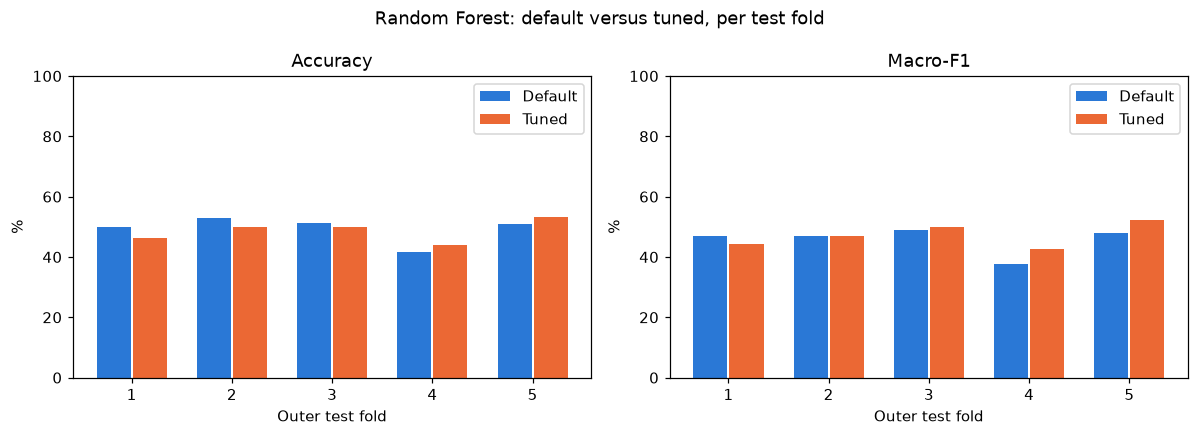

In [9]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4))
for axis, metric, title in zip(axes, ['accuracy', 'macro_f1'], ['Accuracy', 'Macro-F1']):
    table = cv.fold_metrics.pivot(index='fold', columns='variant', values=metric)[VARIANTS]
    positions = np.arange(len(table))
    for k, (variant, color) in enumerate(zip(VARIANTS, [BLUE, ORANGE])):
        axis.bar(positions + (k - 0.5)*0.36, 100*table[variant], width=0.34, color=color, label=variant)
    axis.set_xticks(positions, table.index)
    axis.set(title=title, xlabel='Outer test fold', ylabel='%', ylim=(0, 100))
    axis.legend(loc='upper right')
figure.suptitle(f'{MODEL_NAME}: default versus tuned, per test fold')
figure.tight_layout()
save_figure(figure, 'fold_performance.png')

## 9. Chosen settings and overfitting check

`inner_best_macro_f1` is the tuning score on the inner folds, not a final result.

For a Random Forest the training accuracy is not a useful overfitting check: a forest of deep trees almost always classifies its own training clips correctly, so 100% says nothing. The **out-of-bag (OOB) accuracy** is better. Every tree is trained on a bootstrap sample, which leaves out about a third of the training clips, and the OOB accuracy tests every training clip only with the trees that did not see it. If the OOB accuracy is close to the outer test accuracy, the forest generalizes as well as its training data suggests.

In [10]:
display(cv.best_parameters.round(4))
display(cv.fold_metrics[['fold', 'variant', 'train_accuracy', 'oob_accuracy', 'accuracy', 'macro_f1']].round(4))

,fold,inner_best_macro_f1,class_weight,max_features,min_samples_leaf
0,1,0.4633,balanced,0.5,1
1,2,0.4720,balanced,sqrt,4
2,3,0.4647,balanced,1.0,1
3,4,0.4937,balanced,sqrt,1
4,5,0.4521,balanced,sqrt,1


,fold,variant,train_accuracy,oob_accuracy,accuracy,macro_f1
0,1,Default,1.0000,0.4910,0.5000,0.4681
1,1,Tuned,1.0000,0.5090,0.4643,0.4431
2,2,Default,1.0000,0.5018,0.5286,0.4690
3,2,Tuned,0.9677,0.4749,0.5000,0.4712
4,3,Default,1.0000,0.5215,0.5143,0.4901
5,3,Tuned,1.0000,0.5036,0.5000,0.4983
6,4,Default,1.0000,0.5116,0.4173,0.3780
7,4,Tuned,1.0000,0.5116,0.4388,0.4268
8,5,Default,1.0000,0.4848,0.5108,0.4781
9,5,Tuned,1.0000,0.4687,0.5324,0.5215


## 10. Confusion matrices, per-genre results and common errors

Rows are the **true genres** and columns the **predicted genres**; the diagonal holds the correct predictions. The second figure divides every row by the number of recordings of that genre, so its diagonal is the recall of each genre. In the per-genre tables, support is the number of recordings; compare precision and recall to see whether a genre is predicted unreliably or is often missed. The error table describes what happened; it does not explain why two genres are confused.

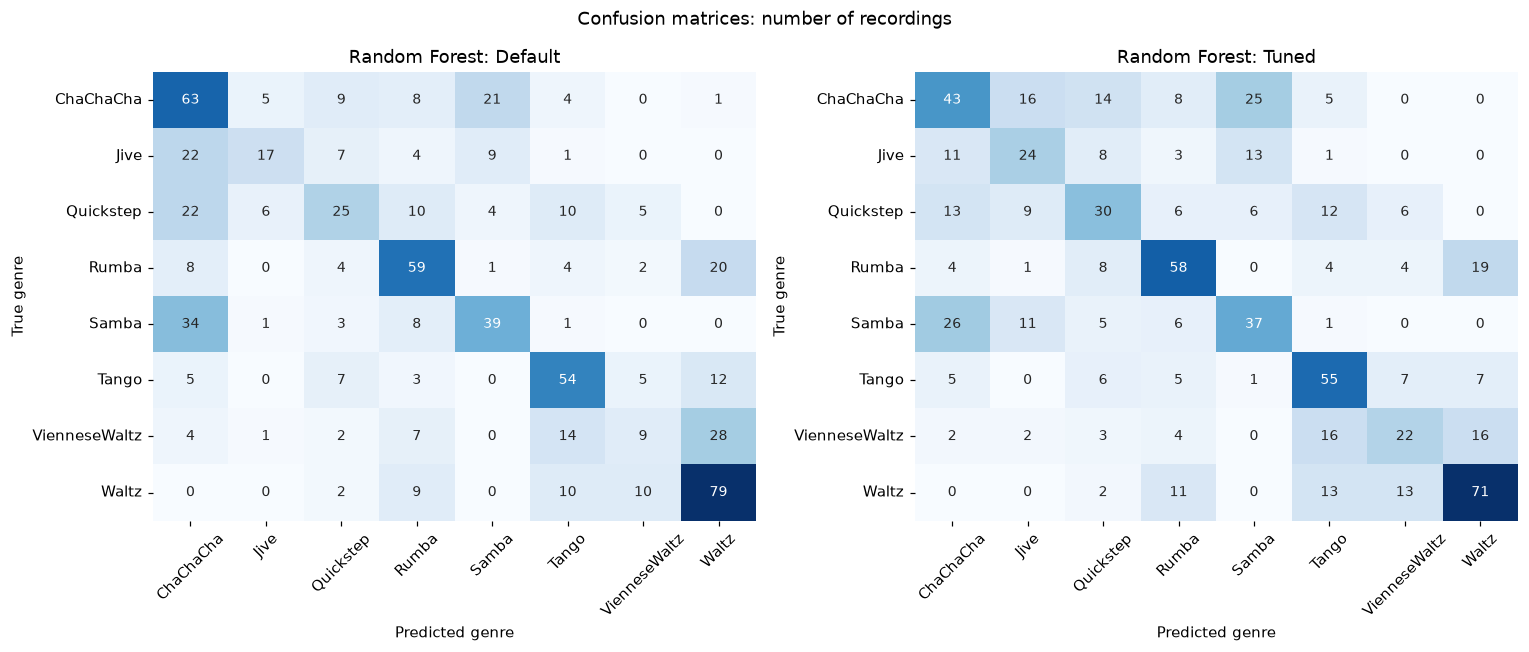

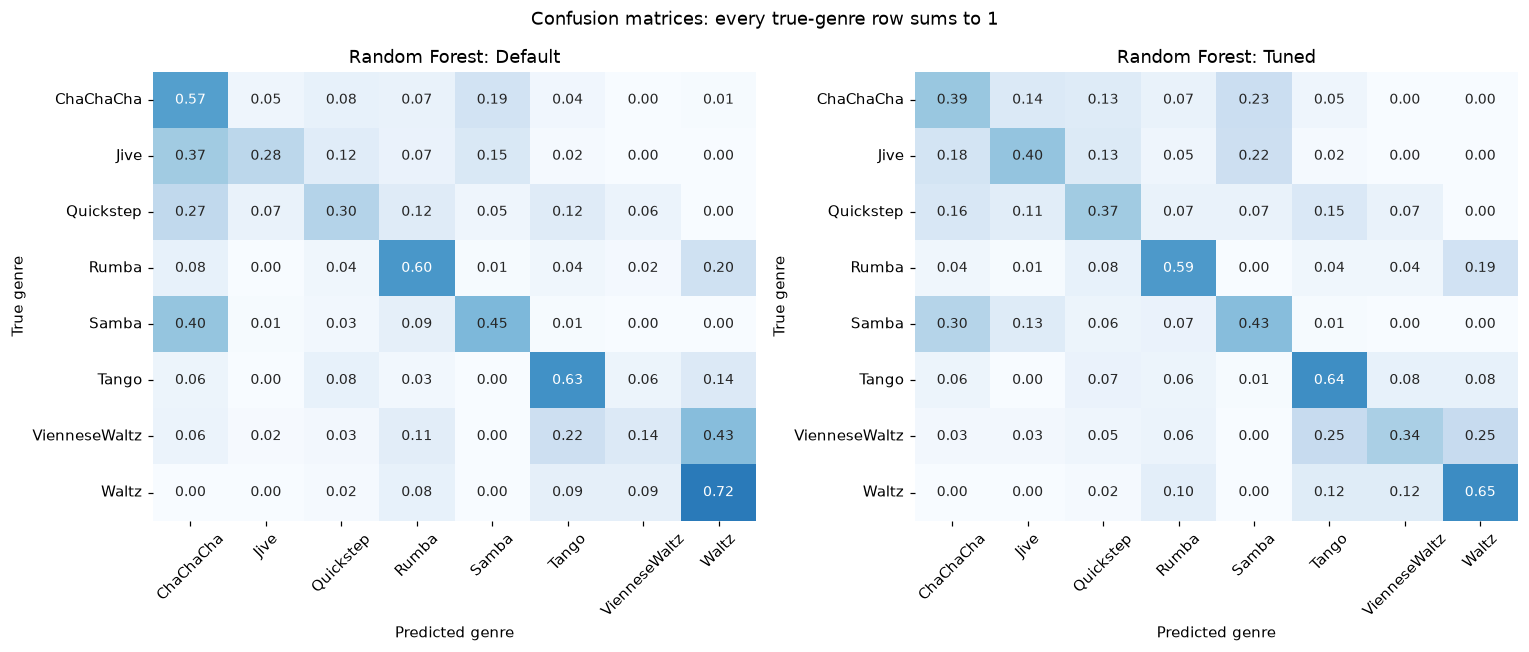

In [11]:
def confusion_tables(y_true, y_pred):
    counts = pd.DataFrame(confusion_matrix(y_true, y_pred, labels=class_labels),
                          index=class_labels, columns=class_labels)
    return counts, counts.div(counts.sum(axis=1), axis=0)


def plot_confusions(tables, titles, fmt, suptitle, ncols=2):
    nrows = int(np.ceil(len(tables)/ncols))
    figure, axes = plt.subplots(nrows, ncols, figsize=(7*ncols, 6*nrows), squeeze=False)
    for axis in axes.flat[len(tables):]:
        axis.set_visible(False)
    for axis, table, title in zip(axes.flat, tables, titles):
        sns.heatmap(table, annot=True, fmt=fmt, cmap='Blues', cbar=False, ax=axis,
                    vmin=0, vmax=None if fmt == 'd' else 1, annot_kws={'size': 9})
        axis.set(title=title, xlabel='Predicted genre', ylabel='True genre')
        axis.tick_params(axis='x', rotation=45)
        axis.tick_params(axis='y', rotation=0)
    figure.suptitle(suptitle)
    figure.tight_layout()
    return figure


def per_genre_report(y_true, y_pred):
    report = pd.DataFrame(classification_report(y_true, y_pred, labels=class_labels,
                                                output_dict=True, zero_division=0)).T.loc[class_labels]
    report['support'] = report['support'].astype(int)
    return report


confusions = {v: confusion_tables(cv.predictions['label'], cv.predictions[f'prediction_{v.lower()}'])
              for v in VARIANTS}
for variant, (counts, normalized) in confusions.items():
    save(counts, f'confusion_counts_{variant.lower()}.csv')
    save(normalized, f'confusion_normalized_{variant.lower()}.csv')
titles = [f'{MODEL_NAME}: {v}' for v in VARIANTS]
save_figure(plot_confusions([confusions[v][0] for v in VARIANTS], titles, 'd',
                            'Confusion matrices: number of recordings'), 'confusion_counts.png')
save_figure(plot_confusions([confusions[v][1] for v in VARIANTS], titles, '.2f',
                            'Confusion matrices: every true-genre row sums to 1'), 'confusion_normalized.png')

In [12]:
for variant in VARIANTS:
    report = per_genre_report(cv.predictions['label'], cv.predictions[f'prediction_{variant.lower()}'])
    save(report, f'per_genre_report_{variant.lower()}.csv', index_label='genre')
    print(f'{variant}: per-genre precision, recall and F1')
    display(report.round(4))

counts = confusions['Tuned'][0]
errors = pd.DataFrame([{'true_genre': t, 'predicted_genre': p, 'clips': int(counts.loc[t, p]),
                        'share_of_true_genre': counts.loc[t, p]/counts.loc[t].sum()}
                       for t in class_labels for p in class_labels if t != p and counts.loc[t, p] > 0])
errors = errors.sort_values('clips', ascending=False).head(10).reset_index(drop=True)
save(errors, 'common_errors_tuned.csv', index=False)
print('Most common errors of the tuned model')
display(errors.round(4))

Default: per-genre precision, recall and F1


,precision,recall,f1-score,support
ChaChaCha,0.3987,0.5676,0.4684,111
Jive,0.5667,0.2833,0.3778,60
Quickstep,0.4237,0.3049,0.3546,82
Rumba,0.5463,0.6020,0.5728,98
Samba,0.5270,0.4535,0.4875,86
Tango,0.5510,0.6279,0.5870,86
VienneseWaltz,0.2903,0.1385,0.1875,65
Waltz,0.5643,0.7182,0.6320,110


Tuned: per-genre precision, recall and F1


,precision,recall,f1-score,support
ChaChaCha,0.4135,0.3874,0.4000,111
Jive,0.3810,0.4000,0.3902,60
Quickstep,0.3947,0.3659,0.3797,82
Rumba,0.5743,0.5918,0.5829,98
Samba,0.4512,0.4302,0.4405,86
Tango,0.5140,0.6395,0.5699,86
VienneseWaltz,0.4231,0.3385,0.3761,65
Waltz,0.6283,0.6455,0.6368,110


Most common errors of the tuned model


,true_genre,predicted_genre,clips,share_of_true_genre
0,Samba,ChaChaCha,26,0.3023
1,ChaChaCha,Samba,25,0.2252
2,Rumba,Waltz,19,0.1939
3,VienneseWaltz,Tango,16,0.2462
4,VienneseWaltz,Waltz,16,0.2462
5,ChaChaCha,Jive,16,0.1441
6,ChaChaCha,Quickstep,14,0.1261
7,Quickstep,ChaChaCha,13,0.1585
8,Jive,Samba,13,0.2167
9,Waltz,VienneseWaltz,13,0.1182


## 11. Which feature families does the tuned model use?

**Group permutation importance:** we shuffle all columns of one family together across the test clips of a fold (so the family's internal relationships stay, but its link to the genre is broken) and measure how much macro-F1 drops. A big drop means the fitted model relies on that family. We repeat the shuffle 5 times per family and fold.

The families have different sizes (26, 2 and 2 columns) and are correlated with each other, so these numbers are not a ranking of single features and not causal effects. This is only for interpretation; all 30 inputs stay in the model.

,mean macro-F1 drop (pp),SD over folds (pp)
feature_family,,
MFCC,29.61,4.58
Spectral centroid,7.35,6.68
Zero-crossing rate,0.48,2.64


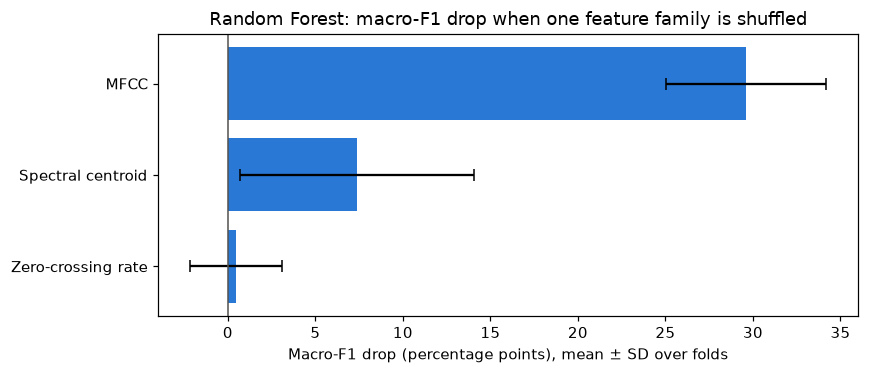

In [13]:
rows = []
for fold, fold_models in cv.models.items():
    test = data['fold'] == fold
    X_test, y_test = data.loc[test, FEATURE_COLUMNS], data.loc[test, 'label']
    model = fold_models['Tuned']
    baseline = f1_score(y_test, model.predict(X_test), average='macro', zero_division=0)
    for family, columns in FEATURE_GROUPS.items():
        for repeat in range(IMPORTANCE_REPEATS):
            order = np.random.default_rng(RANDOM_SEED + 100*fold + repeat).permutation(len(X_test))
            shuffled = X_test.copy()
            shuffled[columns] = X_test[columns].to_numpy()[order]
            score = f1_score(y_test, model.predict(shuffled), average='macro', zero_division=0)
            rows.append({'fold': fold, 'feature_family': family, 'macro_f1_drop': baseline - score})

per_fold = pd.DataFrame(rows).groupby(['fold', 'feature_family'])['macro_f1_drop'].mean()
importance = per_fold.groupby('feature_family').agg(['mean', 'std']).sort_values('mean', ascending=False)
save(importance, 'feature_family_importance.csv')
display((100*importance).rename(columns={'mean': 'mean macro-F1 drop (pp)', 'std': 'SD over folds (pp)'}).round(2))

figure, axis = plt.subplots(figsize=(8, 3.5))
positions = np.arange(len(importance))
axis.barh(positions, 100*importance['mean'], xerr=100*importance['std'], color=BLUE, capsize=4)
axis.set_yticks(positions, importance.index)
axis.invert_yaxis()
axis.axvline(0, color='#52514e', linewidth=1)
axis.set(title=f'{MODEL_NAME}: macro-F1 drop when one feature family is shuffled',
         xlabel='Macro-F1 drop (percentage points), mean ± SD over folds')
figure.tight_layout()
save_figure(figure, 'feature_family_importance.png')

## 12. Feature choice check: without `mfcc_00`

`mfcc_00` mostly measures how loud a recording is, and loudness depends on the mastering of an album as much as on the instruments. If a model relied on it, it could be recognizing albums instead of dance styles. So we run the same nested cross-validation (same folds, same search) without `mfcc_00_mean` and `mfcc_00_std` (28 inputs) and compare.

This is a sensitivity check, not a selection step: the main model stays the 30-input model whatever the result, because choosing features by their test score would make the test score too optimistic.

In [14]:
without_c0 = [c for c in FEATURE_COLUMNS if not c.startswith('mfcc_00')]
cv_without_c0 = run_nested_cv(data, without_c0, verbose=False)

feature_check = pd.concat([
    summarize_folds(cv.fold_metrics, ['accuracy', 'macro_f1']).assign(inputs='all 30'),
    summarize_folds(cv_without_c0.fold_metrics, ['accuracy', 'macro_f1']).assign(inputs='without mfcc_00 (28)'),
])
feature_check['label'] = feature_check['inputs'] + ', ' + feature_check['variant']
save(feature_check, 'feature_check_without_mfcc00.csv', index=False)
display(mean_sd_table(feature_check, ['accuracy', 'macro_f1'], index='label'))
print('Per fold: macro-F1 without mfcc_00 minus with it (percentage points)')
display(paired_differences(cv.fold_metrics, cv_without_c0.fold_metrics,
                           names=('all 30', 'without mfcc_00')).round(2))

label,"all 30, Default","all 30, Tuned","without mfcc_00 (28), Default","without mfcc_00 (28), Tuned"
accuracy,49.42 ± 4.42,48.71 ± 3.62,49.14 ± 3.79,47.71 ± 2.81
macro_f1,45.66 ± 4.49,47.22 ± 3.88,45.88 ± 3.32,46.11 ± 3.29


Per fold: macro-F1 without mfcc_00 minus with it (percentage points)


variant,Default,Tuned
fold,,
1,-0.25,0.66
2,-0.85,-1.75
3,-4.59,0.18
4,3.84,-1.05
5,2.93,-3.56


## 13. Compare the two classifiers

Both notebooks make the same folds, so the two models are tested on exactly the same recordings in every fold. That makes a **paired** comparison possible: for every fold we subtract the other model's macro-F1 from this model's. Even if the differences have the same sign in all five folds, five folds are too few to call the gap significant (a sign test then gives p ≈ 0.06).

How the two models differ, which helps to explain the results:

* **Random Forest** splits on one feature at a time with thresholds. It doesn't need scaling, and it can pick out a few strong features and ignore the rest.
* **SVM–RBF** compares whole feature vectors by their distance after standardization, so every input counts in every decision, and the decision boundary is smooth.
* Under time-stretching, a forest's prediction can jump when one feature crosses a split threshold, while the SVM's decision changes gradually. Compare the flip rates in section 17 to see whether this shows up.

This cell needs the SVM–RBF notebook (`Timbral_SVM_RBF.ipynb`) to have run. If it hasn't, run it and then rerun this cell.

In [15]:
other_metrics_path = OTHER_RESULTS_DIR / 'fold_metrics.csv'
other_predictions_path = OTHER_RESULTS_DIR / 'out_of_fold_predictions.csv'

if other_metrics_path.is_file() and other_predictions_path.is_file():
    other_metrics = pd.read_csv(other_metrics_path)
    other_folds = pd.read_csv(other_predictions_path).set_index('filename')['fold']
    this_folds = cv.predictions.set_index('filename')['fold']
    assert other_folds.loc[this_folds.index].equals(this_folds), 'the two notebooks used different folds'

    both = pd.concat([summarize_folds(cv.fold_metrics, ['accuracy', 'macro_f1']).assign(model=MODEL_NAME),
                      summarize_folds(other_metrics, ['accuracy', 'macro_f1']).assign(model=OTHER_MODEL_NAME)])
    both['label'] = both['model'] + ', ' + both['variant']
    print('Same recordings and folds, mean ± SD (%)')
    display(mean_sd_table(both, ['accuracy', 'macro_f1'], index='label'))
    print(f'Per fold: macro-F1 of {MODEL_NAME} minus {OTHER_MODEL_NAME} (percentage points)')
    display(paired_differences(other_metrics, cv.fold_metrics, names=(OTHER_MODEL_NAME, MODEL_NAME)).round(2))
else:
    print(f'Run the {OTHER_MODEL_NAME} notebook, then rerun this cell to compare the two models.')

Same recordings and folds, mean ± SD (%)


label,"Random Forest, Default","Random Forest, Tuned","SVM–RBF, Default","SVM–RBF, Tuned"
accuracy,49.42 ± 4.42,48.71 ± 3.62,50.57 ± 4.20,49.57 ± 3.47
macro_f1,45.66 ± 4.49,47.22 ± 3.88,47.12 ± 3.80,47.20 ± 3.77


Per fold: macro-F1 of Random Forest minus SVM–RBF (percentage points)


variant,Default,Tuned
fold,,
1,2.30,-0.04
2,-3.46,-1.43
3,1.83,4.27
4,-4.49,-1.67
5,-3.46,-1.05


---
# TIME-STRETCH EXPERIMENT STARTS HERE

## 14. Question, conditions and controls

**Question:** do the held-out predictions of the timbral models change when the tempo of the audio changes while the pitch stays the same?

Every clip is analysed in 13 versions:

| Condition | Tempo change | What it tests |
|---|---|---|
| `original` | 0% | baseline: fresh features of the unchanged audio |
| `stretch_0.90` … `stretch_1.10` | −10%, −5%, −2%, +2%, +5%, +10% | tempo change **plus** processing artifacts |
| `roundtrip_0.90` … `roundtrip_1.10` | 0% (stretched by r, then by 1/r) | processing artifacts only, applied twice |

`stretch_1.10` plays the clip 10% faster, so it gets about 9.1% shorter. The stretching uses librosa's **phase vocoder** (`librosa.effects.time_stretch`), which changes the speed by recomputing the phase of every frequency bin from frame to frame, so the pitch stays the same.

How to read the results: if a model gets worse on `stretch_r` but not on `roundtrip_r`, the change comes from the **tempo**. If it gets as much worse on both, it comes from the **processing**. The round trip processes the audio twice, so its damage is an upper estimate of the artifacts in `stretch_r`. The ±2% stretches are the smallest tempo change, not a control, since they change the tempo too.

In [16]:
RATES = [0.90, 0.95, 0.98, 1.02, 1.05, 1.10]


def make_condition(kind, rate):
    name = 'original' if kind == 'original' else f'{kind}_{rate:.2f}'
    tempo_change = 100*(rate - 1) if kind == 'stretch' else 0.0
    return {'condition': name, 'kind': kind, 'rate': rate, 'tempo_change_percent': round(tempo_change, 6)}


CONDITIONS = ([make_condition('original', 1.0)]
              + [make_condition('stretch', rate) for rate in RATES]
              + [make_condition('roundtrip', rate) for rate in RATES])


def change_tempo(y, rate):
    # plays y `rate` times as fast with the same pitch
    # (computed in 64-bit floats, then stored as 32-bit like the loaded audio)
    if rate == 1.0:
        return y
    stretched = librosa.effects.time_stretch(y.astype(np.float64), rate=rate, n_fft=2048, hop_length=512)
    return stretched.astype(np.float32)


def apply_condition(y, condition):
    if condition['kind'] == 'original':
        return y
    if condition['kind'] == 'stretch':
        return change_tempo(y, condition['rate'])
    if condition['kind'] == 'roundtrip':
        return change_tempo(change_tempo(y, condition['rate']), 1.0/condition['rate'])
    raise ValueError(f'unknown condition: {condition}')


display(pd.DataFrame(CONDITIONS))

,condition,kind,rate,tempo_change_percent
0,original,original,1.00,0.0
1,stretch_0.90,stretch,0.90,-10.0
2,stretch_0.95,stretch,0.95,-5.0
3,stretch_0.98,stretch,0.98,-2.0
4,stretch_1.02,stretch,1.02,2.0
5,stretch_1.05,stretch,1.05,5.0
6,stretch_1.10,stretch,1.10,10.0
7,roundtrip_0.90,roundtrip,0.90,0.0
8,roundtrip_0.95,roundtrip,0.95,0.0
9,roundtrip_0.98,roundtrip,0.98,0.0


## 15. Features of the stretched clips

The features of every version are computed with **exactly the same settings as the main (librosa) version of `Timbral_extraction.py`**. The check below compares the fresh `original` rows with `ballroom_timbral_features.csv`; if they differed, the comparison would not be fair and the notebook stops.

This takes about 15 minutes, so the result is saved in `timbral_conditions.csv`:

* if the file is already complete (for example because the other notebook made it), it is reused, so both models are tested on identical features,
* otherwise the features are computed from the audio in `DATASET_DIR`, 25 clips at a time. The progress is saved after every batch in `timbral_conditions_partial.csv`, so if the run is interrupted, running the cell again continues where it stopped. Don't run the two notebooks at the same time while this file is being made.

If there is neither audio nor a saved file, sections 15-20 print a message and are skipped.

In [17]:
SR, N_FFT, HOP_LENGTH, N_MFCC, N_MELS = 22050, 2048, 512, 13, 128   # same as Timbral_extraction.py


def load_audio(path):
    y, _ = librosa.load(path, sr=SR, mono=True)
    if len(y) < N_FFT:
        raise ValueError('audio is too short')
    if np.max(np.abs(y)) == 0:
        raise ValueError('audio is silent')
    return y


def timbral_features(y):
    # the main (librosa) version of Timbral_extraction.py: 30 numbers per clip
    mfcc = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=N_MFCC, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS)
    zcr = librosa.feature.zero_crossing_rate(y, frame_length=N_FFT, hop_length=HOP_LENGTH)[0]
    sc = librosa.feature.spectral_centroid(y=y, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH)[0]
    feats = {}
    for i in range(N_MFCC):
        feats[f'mfcc_{i:02d}_mean'] = float(np.mean(mfcc[i]))
        feats[f'mfcc_{i:02d}_std'] = float(np.std(mfcc[i]))
    feats['zcr_mean'], feats['zcr_std'] = float(np.mean(zcr)), float(np.std(zcr))
    feats['spectral_centroid_mean'], feats['spectral_centroid_std'] = float(np.mean(sc)), float(np.std(sc))
    return feats


def condition_rows(path, clip):
    # the features of one clip in all 13 conditions; errors are returned, not hidden
    try:
        y = load_audio(path)
        rows = []
        for condition in CONDITIONS:
            y_condition = apply_condition(y, condition)
            rows.append({**clip, **condition, 'duration': len(y_condition)/SR,
                         'original_duration': len(y)/SR, **timbral_features(y_condition)})
        return rows, None
    except Exception as e:
        return [], {'filename': clip['filename'], 'error': repr(e)}


def is_complete(path):
    # True if a saved conditions file has every clip in every condition
    if not path.is_file():
        return False
    saved = pd.read_csv(path, usecols=['filename', 'condition'])
    return (len(saved) == len(data)*len(CONDITIONS) and set(saved['filename']) == set(data['filename'])
            and set(saved['condition']) == {c['condition'] for c in CONDITIONS})


def extract_conditions(batch_size=25):
    partial = CONDITIONS_PATH.with_name('timbral_conditions_partial.csv')
    done = set(pd.read_csv(partial, usecols=['filename'])['filename']) if partial.is_file() else set()
    todo = data[~data['filename'].isin(done)]
    print(f'{len(done)} clips already done, {len(todo)} to go (using {N_JOBS} cores)')
    failed = []
    for start in range(0, len(todo), batch_size):
        batch = todo.iloc[start:start + batch_size]
        jobs = (delayed(condition_rows)(DATASET_DIR / clip['folder'] / clip['filename'],
                                        {k: clip[k] for k in ['track_id', 'filename', 'folder', 'label']})
                for _, clip in batch.iterrows())
        results = Parallel(n_jobs=N_JOBS)(jobs)
        rows = [row for clip_rows, _ in results for row in clip_rows]
        failed += [error for _, error in results if error is not None]
        if rows:
            pd.DataFrame(rows).to_csv(partial, mode='a', header=not partial.is_file(), index=False)
        print(f'  {len(done) + start + len(batch)} of {len(data)} clips', flush=True)
    if failed:
        raise RuntimeError(f'{len(failed)} clips failed (the others are saved, rerun to retry them): {failed[:5]}')
    table = pd.read_csv(partial)
    table.to_csv(CONDITIONS_PATH, index=False)
    partial.unlink()
    return table


if is_complete(CONDITIONS_PATH):
    source = CONDITIONS_PATH
    print(f'using the saved stretched features in {CONDITIONS_PATH}')
elif DATASET_DIR.is_dir():
    start = time.perf_counter()
    extract_conditions()
    source = CONDITIONS_PATH
    print(f'computed in {(time.perf_counter() - start)/60:.1f} minutes')
else:
    source = None
    print(f'No audio in {DATASET_DIR.resolve()} and no saved stretched features: '
          'sections 15-20 are skipped. Extract data1.tar.gz into the project folder and rerun from here.')
STRETCH_READY = source is not None

using the saved stretched features in timbral_conditions.csv


Checks on the stretched features: every clip in every condition; the fresh `original` rows must agree with the training table (the largest difference per feature must be below 5% of how much that feature varies between clips, and is normally very small); and every version must have the expected length (original duration divided by r for `stretch_r`, the original duration for `roundtrip_r`).

In [18]:
if STRETCH_READY:
    conditions = pd.read_csv(source)
    conditions['label'] = merge_rumba(conditions['label']).to_numpy()
    assert is_complete(source) and not conditions.duplicated(['filename', 'condition']).any()

    fresh = conditions[conditions['condition'] == 'original'].set_index('filename').loc[data['filename'], FEATURE_COLUMNS]
    difference = np.abs(fresh.to_numpy() - data[FEATURE_COLUMNS].to_numpy()).max(axis=0)
    agreement = pd.DataFrame({'largest_difference': difference,
                              'difference_over_spread': difference/data[FEATURE_COLUMNS].std().to_numpy()},
                             index=FEATURE_COLUMNS)
    agreement.to_csv(STRETCH_DIR / 'original_extraction_agreement.csv')
    print(f'fresh original rows vs training table: largest difference / spread = '
          f'{agreement["difference_over_spread"].max():.2e}')
    assert (agreement['difference_over_spread'] < 0.05).all(), \
        'the fresh features differ from ballroom_timbral_features.csv; were they made with other settings?'

    expected = np.where(conditions['kind'] == 'stretch', conditions['original_duration']/conditions['rate'],
                        conditions['original_duration'])
    duration_error = np.abs(conditions['duration'] - expected).max()
    print(f'largest duration error: {duration_error*SR:.2f} samples')
    assert duration_error <= 2/SR

fresh original rows vs training table: largest difference / spread = 6.03e-03
largest duration error: 1.00 samples


## 16. Predict every condition with the original fold models

The fold models from section 7 are used as they are: trained and tuned on the original audio only, never refitted, and the SVM's scaler stays as it was fitted on the training clips. Only `.predict()` is called on the changed audio. Every version of a clip keeps the clip's genre label and test fold.

The **paired baseline** is the prediction on the fresh `original` features: the flip rate (share of clips whose prediction changes) and the metric changes compare the same clips with the same model.

In [19]:
CONDITION_ORDER = pd.DataFrame(CONDITIONS)['condition'].tolist()

if STRETCH_READY:
    by_condition = {name: rows.set_index('filename') for name, rows in conditions.groupby('condition')}
    metric_rows, prediction_rows = [], []
    for fold, fold_models in cv.models.items():
        test_files = data.loc[data['fold'] == fold, 'filename']
        y_test = data.loc[data['fold'] == fold, 'label'].to_numpy()
        for variant, model in fold_models.items():
            baseline = model.predict(by_condition['original'].loc[test_files, FEATURE_COLUMNS])
            baseline_scores = classification_scores(y_test, baseline)
            for condition in CONDITIONS:
                predicted = model.predict(by_condition[condition['condition']].loc[test_files, FEATURE_COLUMNS])
                scores = classification_scores(y_test, predicted)
                metric_rows.append({'fold': fold, 'variant': variant, **condition, **scores,
                                    'flip_rate': np.mean(predicted != baseline),
                                    'accuracy_change_pp': 100*(scores['accuracy'] - baseline_scores['accuracy']),
                                    'macro_f1_change_pp': 100*(scores['macro_f1'] - baseline_scores['macro_f1'])})
                prediction_rows.append(pd.DataFrame({'filename': test_files.to_numpy(), 'label': y_test,
                                                     'fold': fold, 'variant': variant,
                                                     'condition': condition['condition'],
                                                     'prediction': predicted, 'baseline_prediction': baseline}))
    condition_metrics = pd.DataFrame(metric_rows)
    condition_predictions = pd.concat(prediction_rows, ignore_index=True)
    condition_metrics.to_csv(STRETCH_DIR / 'fold_metrics.csv', index=False)
    condition_predictions.to_csv(STRETCH_DIR / 'held_out_predictions.csv', index=False)

    fresh_predictions = condition_predictions[condition_predictions['condition'] == 'original']
    for variant in VARIANTS:
        fresh_variant = fresh_predictions[fresh_predictions['variant'] == variant].set_index('filename')['prediction']
        trained = cv.predictions.set_index('filename')[f'prediction_{variant.lower()}']
        print(f'{variant}: {int((fresh_variant != trained.loc[fresh_variant.index]).sum())} of '
              f'{len(fresh_variant)} predictions differ between the fresh original features and the training table')

Default: 0 of 698 predictions differ between the fresh original features and the training table
Tuned: 1 of 698 predictions differ between the fresh original features and the training table


## 17. Results: accuracy, macro-F1 and flip rate per condition

Mean ± SD over the same five test folds in every condition. The paired change compares each condition with the original audio **within the same fold**; negative values mean lower performance. A flip can fix an error as well as cause one, so a high flip rate does not have to lower the accuracy.

In the plots, the solid blue line is the stretched audio (tempo changed) and the dashed orange line the round trip with the same stretch (tempo restored). If the two lines stay together, the change comes from processing, not from tempo. Do not choose hyperparameters from these curves: they are test results.

In [20]:
if STRETCH_READY:
    stretch_summary = summarize_folds(condition_metrics,
                                      ['accuracy', 'macro_f1', 'flip_rate', 'accuracy_change_pp', 'macro_f1_change_pp'],
                                      by=('variant', 'condition', 'kind', 'rate', 'tempo_change_percent'))
    stretch_summary.to_csv(STRETCH_DIR / 'robustness_summary.csv', index=False)

    table = stretch_summary[['variant', 'condition', 'tempo_change_percent']].copy()
    for metric in ['accuracy', 'macro_f1', 'flip_rate']:
        table[f'{metric} (%)'] = [f'{100*m:.2f} ± {100*s:.2f}' for m, s in
                                  zip(stretch_summary[f'{metric}_mean'], stretch_summary[f'{metric}_std'])]
    table['accuracy change (pp)'] = stretch_summary['accuracy_change_pp_mean'].round(2)
    table['macro-F1 change (pp)'] = stretch_summary['macro_f1_change_pp_mean'].round(2)
    display(table.reset_index(drop=True))

,variant,condition,tempo_change_percent,accuracy (%),macro_f1 (%),flip_rate (%),accuracy change (pp),macro-F1 change (pp)
0,Default,original,0.0,49.42 ± 4.42,45.66 ± 4.49,0.00 ± 0.00,0.00,0.00
1,Default,stretch_0.90,-10.0,47.13 ± 3.83,43.23 ± 3.51,16.19 ± 0.96,-2.29,-2.43
2,Default,stretch_0.95,-5.0,48.42 ± 3.79,44.48 ± 3.91,15.47 ± 1.71,-1.00,-1.19
3,Default,stretch_0.98,-2.0,47.56 ± 3.13,43.53 ± 2.58,16.76 ± 3.00,-1.86,-2.14
4,Default,stretch_1.02,2.0,47.99 ± 4.51,44.21 ± 4.62,15.18 ± 3.24,-1.43,-1.45
5,Default,stretch_1.05,5.0,48.70 ± 4.51,45.00 ± 4.13,16.62 ± 4.02,-0.71,-0.66
6,Default,stretch_1.10,10.0,47.27 ± 2.77,43.69 ± 3.11,17.19 ± 2.50,-2.15,-1.97
7,Default,roundtrip_0.90,0.0,47.27 ± 4.39,42.62 ± 4.47,22.06 ± 4.45,-2.14,-3.04
8,Default,roundtrip_0.95,0.0,46.84 ± 3.95,42.51 ± 4.29,22.78 ± 4.46,-2.57,-3.15
9,Default,roundtrip_0.98,0.0,47.42 ± 3.84,42.96 ± 2.96,25.65 ± 4.46,-2.00,-2.70


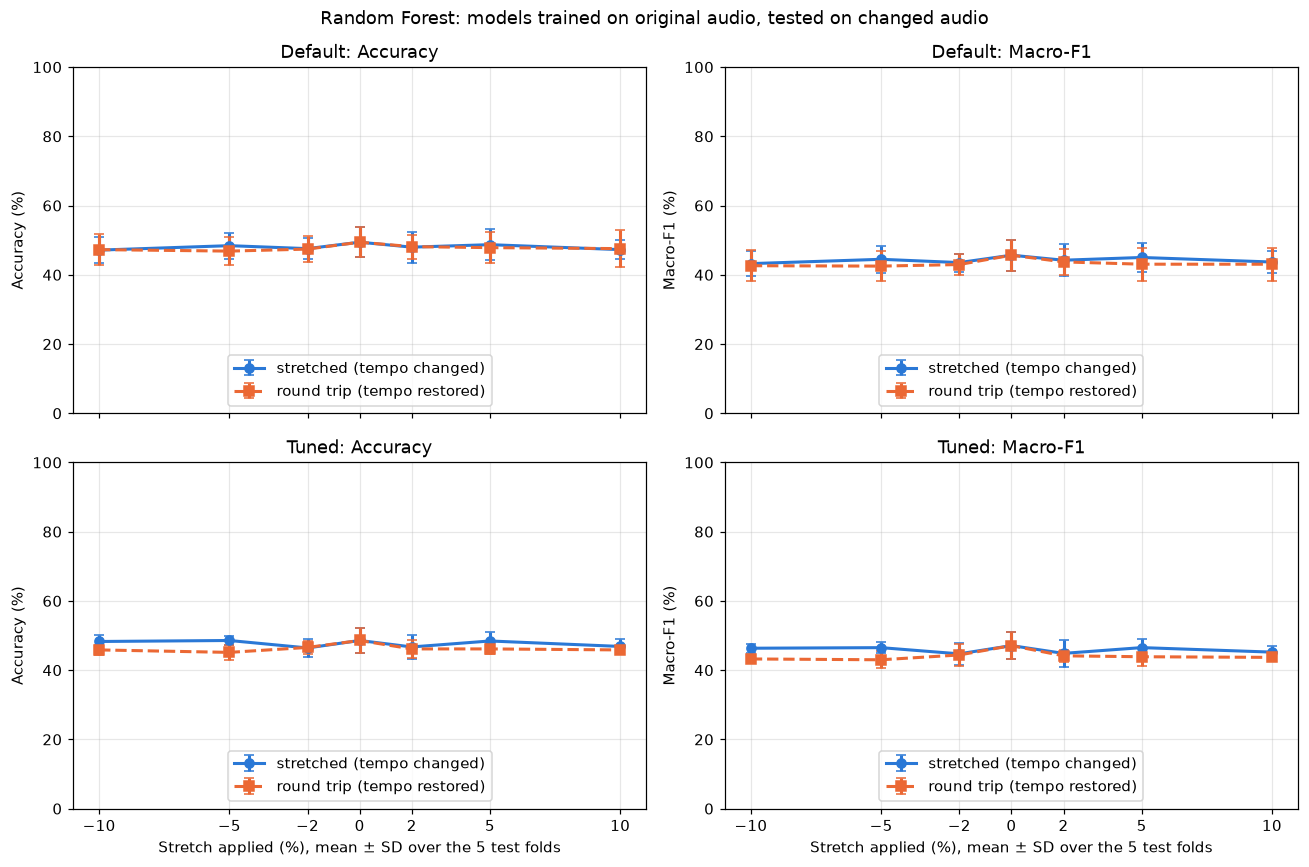

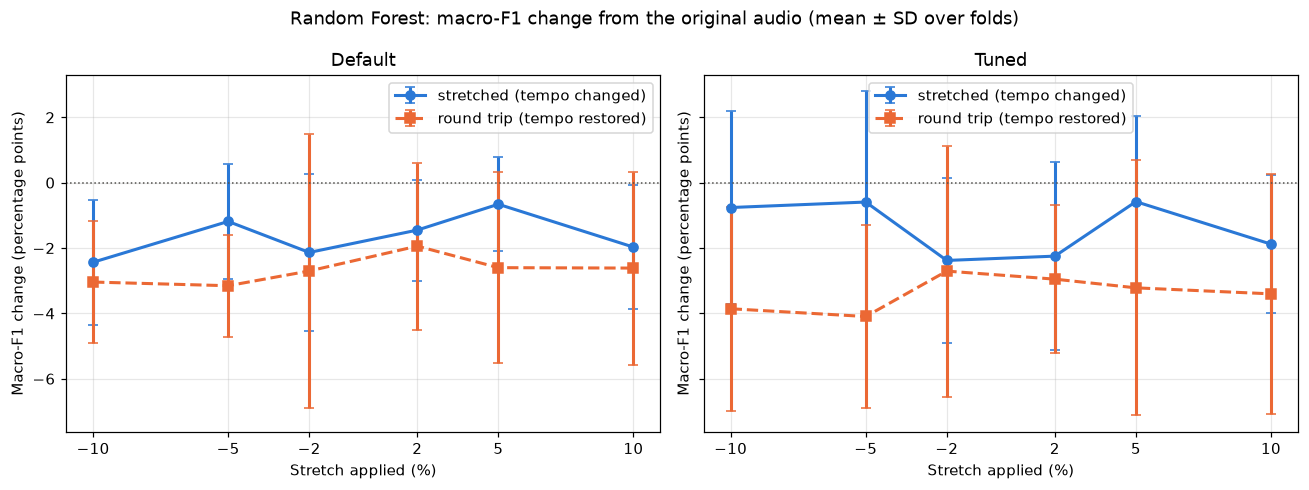

In [21]:
LINES = [('stretch', BLUE, '-', 'o', 'stretched (tempo changed)'),
         ('roundtrip', ORANGE, '--', 's', 'round trip (tempo restored)')]

if STRETCH_READY:
    figure, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
    for row, variant in enumerate(VARIANTS):
        rows = stretch_summary[stretch_summary['variant'] == variant]
        for col, (metric, label) in enumerate([('accuracy', 'Accuracy'), ('macro_f1', 'Macro-F1')]):
            axis = axes[row, col]
            for kind, color, style, marker, legend in LINES:
                part = rows[rows['kind'].isin([kind, 'original'])].sort_values('rate')
                axis.errorbar(100*(part['rate'] - 1), 100*part[f'{metric}_mean'], yerr=100*part[f'{metric}_std'],
                              color=color, linestyle=style, marker=marker, markersize=6, linewidth=2,
                              capsize=3, label=legend)
            axis.set(ylim=(0, 100), ylabel=f'{label} (%)', title=f'{variant}: {label}')
            axis.set_xticks([-10, -5, -2, 0, 2, 5, 10])
            axis.grid(alpha=0.3)
            axis.legend(loc='lower center')
    for axis in axes[1]:
        axis.set_xlabel('Stretch applied (%), mean ± SD over the 5 test folds')
    figure.suptitle(f'{MODEL_NAME}: models trained on original audio, tested on changed audio')
    figure.tight_layout()
    figure.savefig(STRETCH_DIR / 'robustness_curves.png', bbox_inches='tight')
    plt.show()

    figure, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
    for axis, variant in zip(axes, VARIANTS):
        rows = stretch_summary[(stretch_summary['variant'] == variant) & (stretch_summary['kind'] != 'original')]
        for kind, color, style, marker, legend in LINES:
            part = rows[rows['kind'] == kind].sort_values('rate')
            axis.errorbar(100*(part['rate'] - 1), part['macro_f1_change_pp_mean'], yerr=part['macro_f1_change_pp_std'],
                          color=color, linestyle=style, marker=marker, markersize=6, linewidth=2, capsize=3,
                          label=legend)
        axis.axhline(0, color='#52514e', linewidth=1, linestyle=':')
        axis.set(title=variant, xlabel='Stretch applied (%)', ylabel='Macro-F1 change (percentage points)')
        axis.set_xticks([-10, -5, -2, 2, 5, 10])
        axis.grid(alpha=0.3)
        axis.legend()
    figure.suptitle(f'{MODEL_NAME}: macro-F1 change from the original audio (mean ± SD over folds)')
    figure.tight_layout()
    figure.savefig(STRETCH_DIR / 'paired_changes.png', bbox_inches='tight')
    plt.show()

## 18. Confusion matrices and per-genre changes

The confusion matrices show the tuned model on the six stretched conditions, pooled over the folds (every true-genre row sums to 1). If faster or slower audio pushed clips towards the genre whose tempo range they move into, it would show up here as off-diagonal cells that grow with the stretch. The heatmaps show how the F1 of every genre changes (blue = better, red = worse), for the stretches and for the round trips.

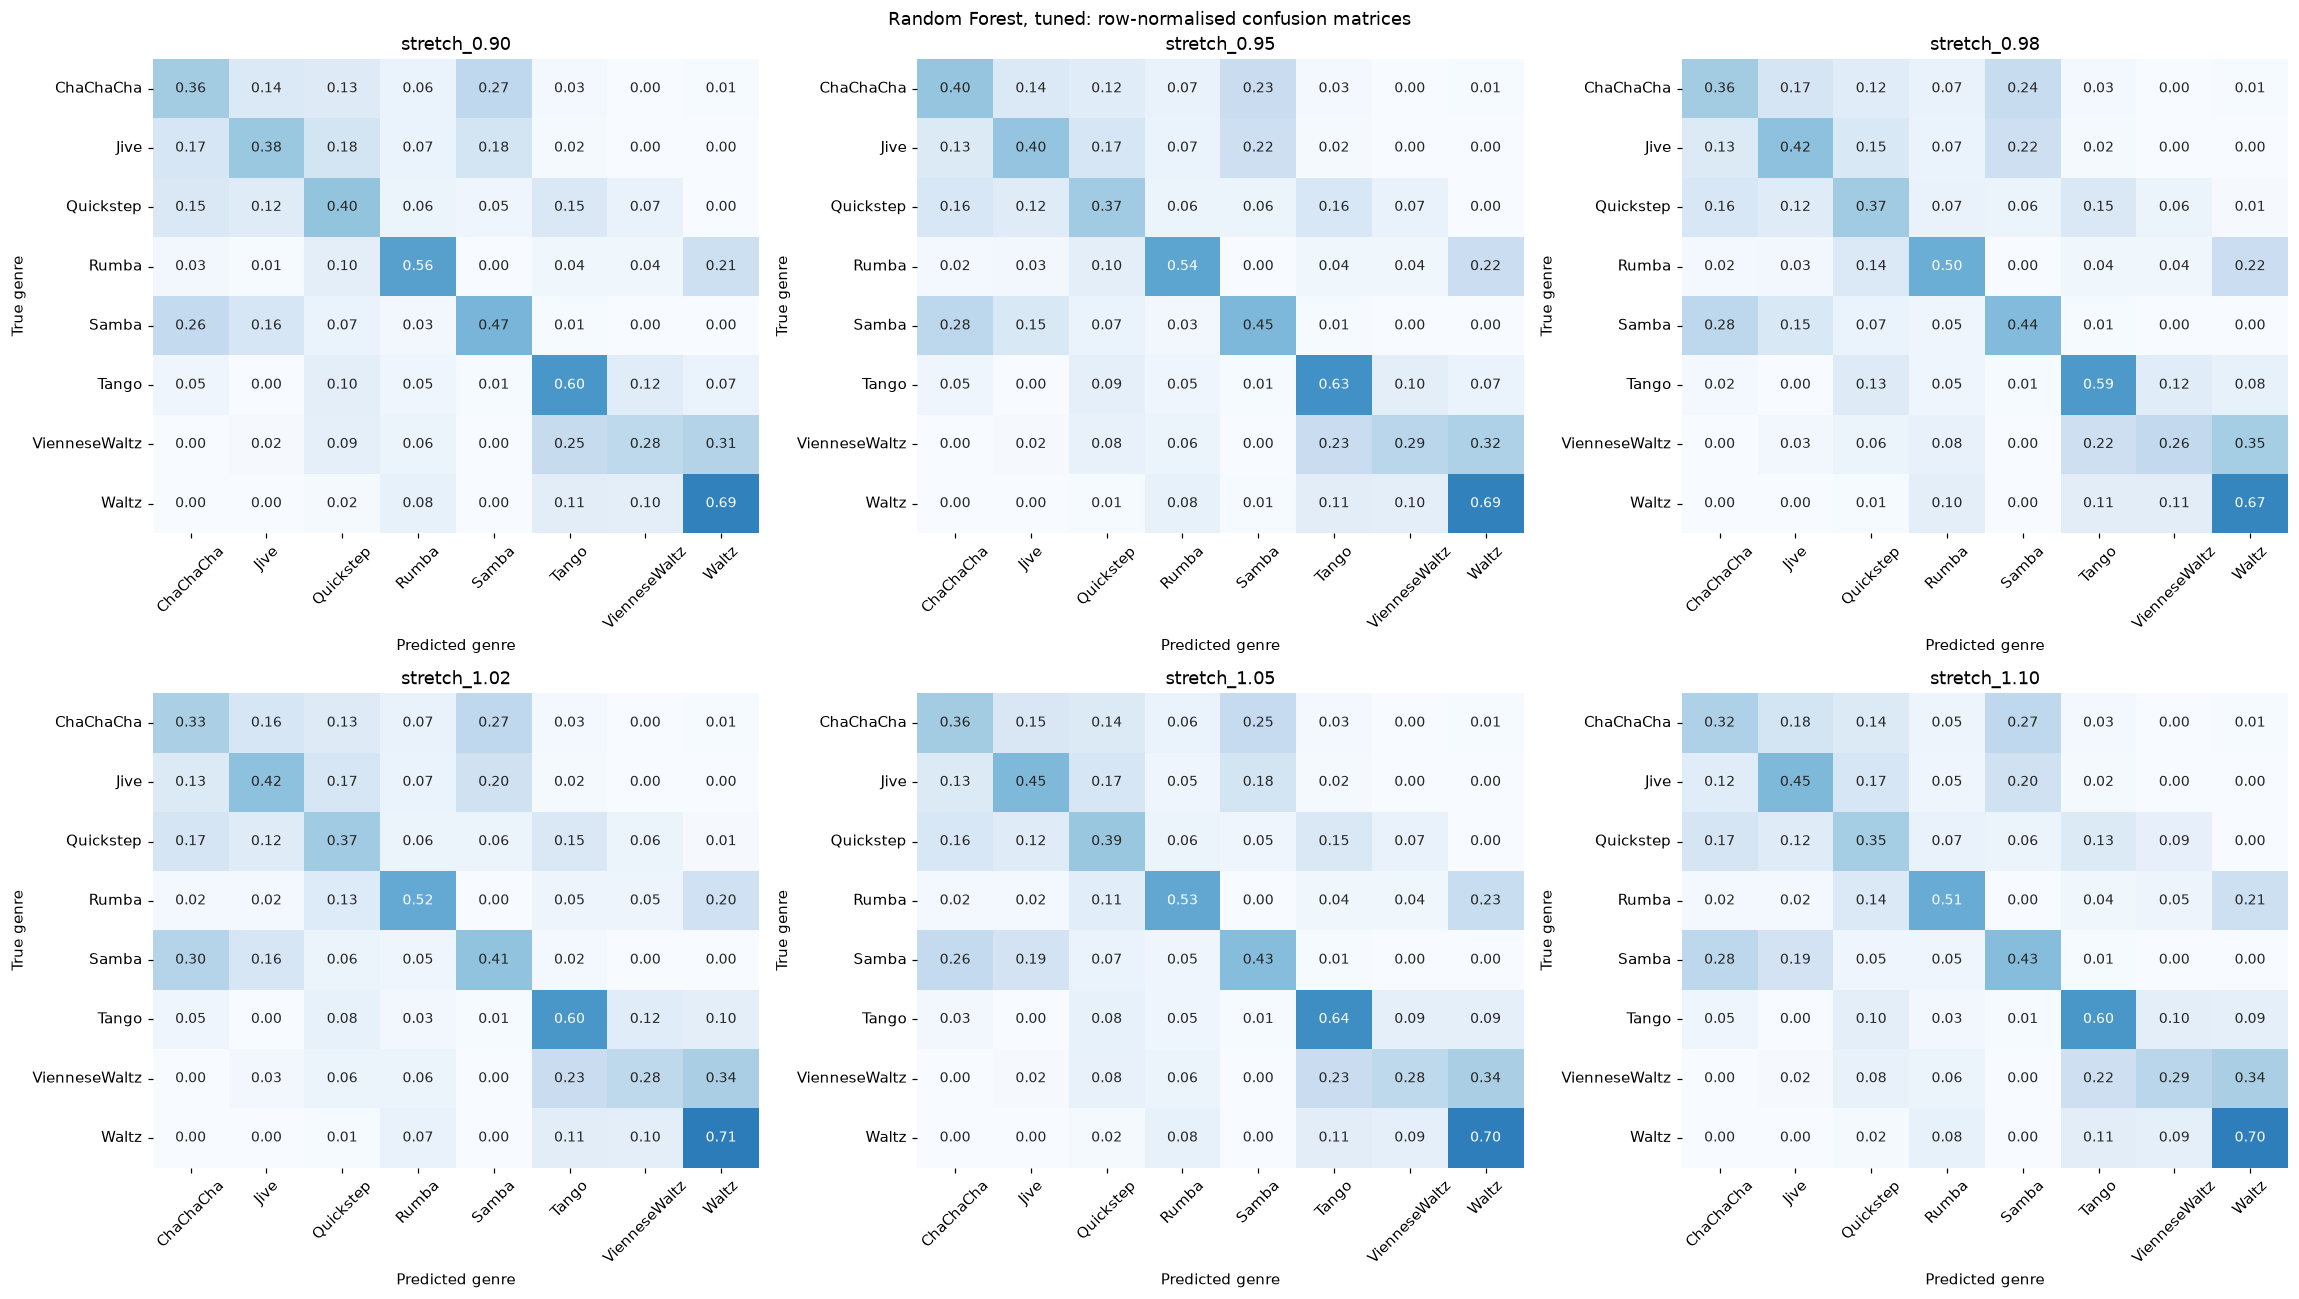

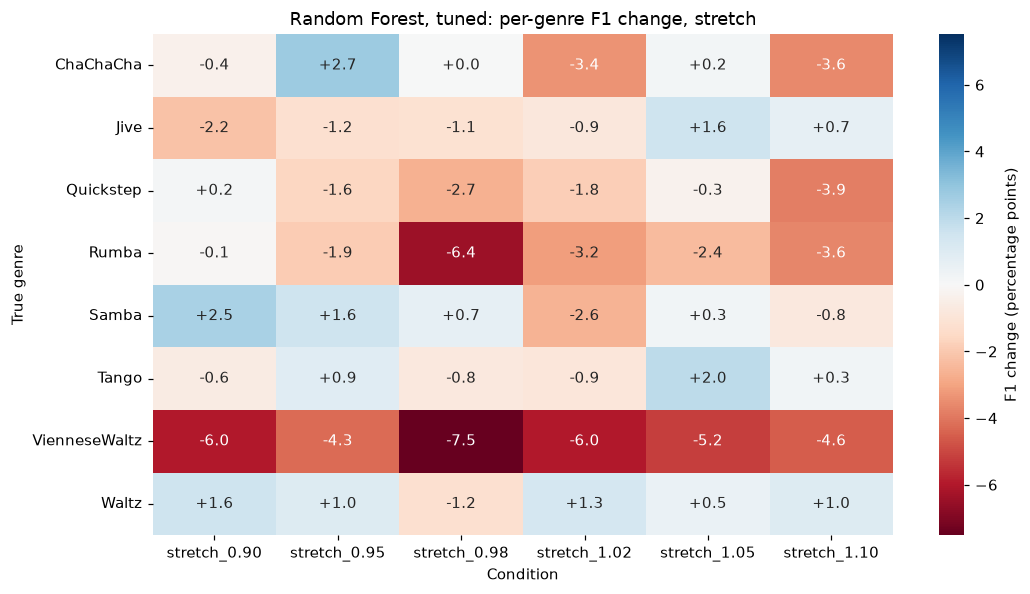

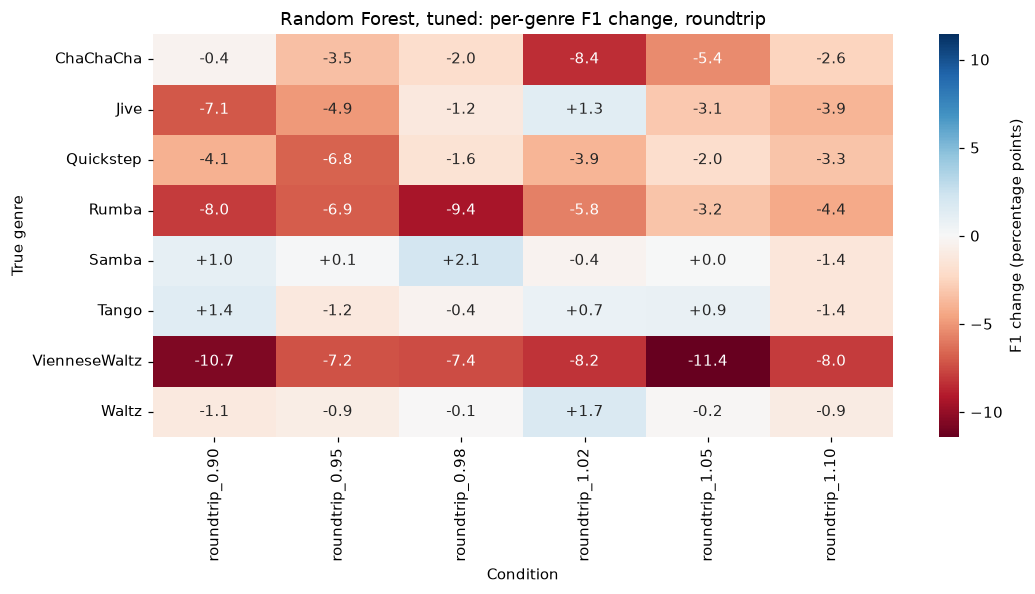

In [22]:
if STRETCH_READY:
    tuned = condition_predictions[condition_predictions['variant'] == 'Tuned']
    stretch_names = [c for c in CONDITION_ORDER if c.startswith('stretch')]
    tables = []
    for name in stretch_names:
        rows = tuned[tuned['condition'] == name]
        tables.append(confusion_tables(rows['label'], rows['prediction'])[1])
    figure = plot_confusions(tables, stretch_names, '.2f', f'{MODEL_NAME}, tuned: row-normalised confusion matrices', ncols=3)
    figure.savefig(STRETCH_DIR / 'confusion_normalized_stretches.png', bbox_inches='tight')
    plt.show()

    f1_by_condition = pd.DataFrame({name: per_genre_report(rows['label'], rows['prediction'])['f1-score']
                                    for name, rows in tuned.groupby('condition')})[CONDITION_ORDER]
    f1_by_condition.to_csv(STRETCH_DIR / 'per_genre_f1_tuned.csv')
    for kind in ['stretch', 'roundtrip']:
        columns = [c for c in CONDITION_ORDER if c.startswith(kind)]
        changes = 100*f1_by_condition[columns].sub(f1_by_condition['original'], axis=0)
        bound = max(1.0, float(np.abs(changes.to_numpy()).max()))
        figure, axis = plt.subplots(figsize=(10, 5.5))
        sns.heatmap(changes, annot=True, fmt='+.1f', cmap='RdBu', center=0, vmin=-bound, vmax=bound, ax=axis,
                    cbar_kws={'label': 'F1 change (percentage points)'})
        axis.set(title=f'{MODEL_NAME}, tuned: per-genre F1 change, {kind}', xlabel='Condition', ylabel='True genre')
        axis.tick_params(axis='y', rotation=0)
        figure.tight_layout()
        figure.savefig(STRETCH_DIR / f'per_genre_f1_change_{kind}.png', bbox_inches='tight')
        plt.show()

## 19. Both classifiers on the same changed audio

This needs the other notebook to have run its time-stretch sections too. Each model keeps the same colour in this plot.

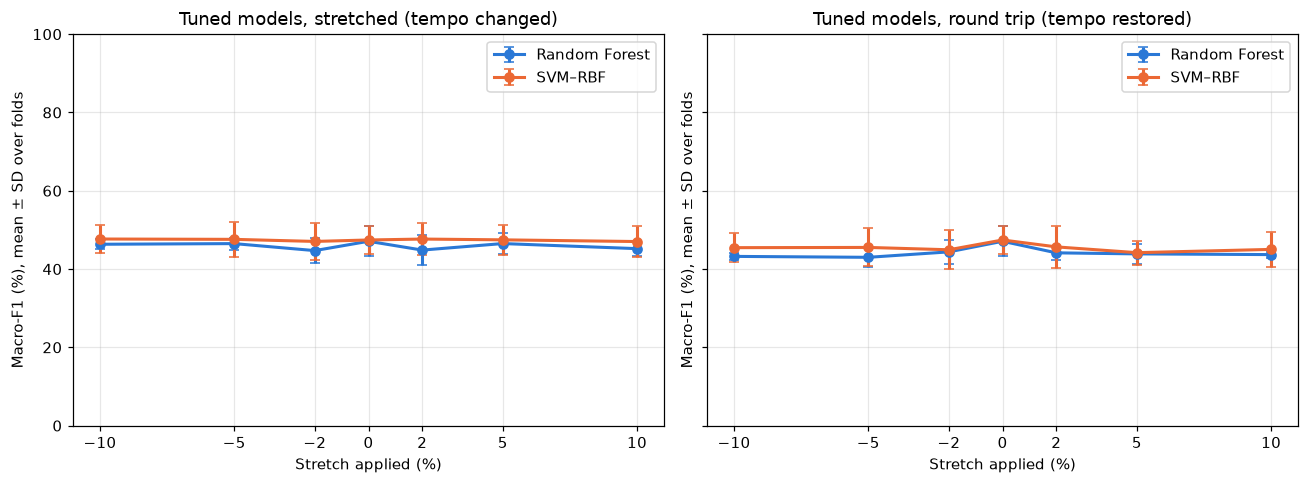

In [23]:
other_summary_path = OTHER_RESULTS_DIR / 'time_stretch' / 'robustness_summary.csv'
if STRETCH_READY and other_summary_path.is_file():
    combined = pd.concat([stretch_summary.assign(model=MODEL_NAME),
                          pd.read_csv(other_summary_path).assign(model=OTHER_MODEL_NAME)])
    combined = combined[combined['variant'] == 'Tuned']
    combined.to_csv(STRETCH_DIR / 'model_comparison.csv', index=False)

    figure, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
    for axis, kind, title in zip(axes, ['stretch', 'roundtrip'],
                                 ['stretched (tempo changed)', 'round trip (tempo restored)']):
        for model, rows in combined.groupby('model'):
            rows = rows[rows['kind'].isin([kind, 'original'])].sort_values('rate')
            axis.errorbar(100*(rows['rate'] - 1), 100*rows['macro_f1_mean'], yerr=100*rows['macro_f1_std'],
                          marker='o', capsize=3, linewidth=2, label=model, color=MODEL_COLORS[model])
        axis.set(title=f'Tuned models, {title}', xlabel='Stretch applied (%)',
                 ylabel='Macro-F1 (%), mean ± SD over folds', ylim=(0, 100))
        axis.set_xticks([-10, -5, -2, 0, 2, 5, 10])
        axis.grid(alpha=0.3)
        axis.legend()
    figure.tight_layout()
    figure.savefig(STRETCH_DIR / 'model_comparison.png', bbox_inches='tight')
    plt.show()
else:
    print('Run the time-stretch sections of both notebooks, then rerun this cell.')

## 20. Points for the report

Describe what the curves show before drawing conclusions; one extreme point does not make a trend.

1. **Tempo or processing?** Compare each `stretch_r` with its `roundtrip_r`. Only the part of the drop that the round trip does not show can be blamed on the tempo. The round trip processes the audio twice, so it overestimates the artifacts.
2. **What timbral features can and can't show.** The mean/std summaries ignore the order of the frames. Stable predictions under stretching therefore say nothing about whether a model understands rhythm; they say that timbre is not where the tempo shortcut lives. That question needs the rhythm and tempo-only models, tested on the same folds (`folds.csv`) and the same stretched audio (`apply_condition`).
3. **Dataset dependence.** The folds keep the 13 known duplicate pairs together, but recordings from the same album can still be in both training and test folds, and albums share mastering and instruments. One duplicate pair has two different labels, so one of the two is always counted as an error.
4. **Labels under tempo change.** Every stretched clip keeps its original label. Dance styles are partly defined by tempo ranges, so near the edge of a range a ±10% change could make the label itself debatable.
5. **Tuning and test data.** Hyperparameters were chosen on the inner folds of the original audio only. The robustness curves are test results and must not be used to choose settings.
6. **Feature choice.** Report the `mfcc_00` check from section 12 as a sensitivity analysis, together with the reason for keeping the 30-input model.